## NBA Player Minutes Predictor - XGBoost Quantile
**- Owner:** Alex

**- Status:** Exploration only. This notebook starts from the saved 14-feature model and tests one change at a time.

**- Last Updated:** 10/19/26

**- Baseline:** Quantile XGBoost saved at `models/saved_models/min_nba_model_2026-04-12.joblib`. Walk-forward q50 pinball 2.226. 2025-26 holdout q50 pinball 2.223, 80% coverage 79.6%, 90% coverage 89.7%.

### Question

**Does adding historical minutes vs matchup improve the model?**

### Decision Criteria
**- Primary metric:** q50 pinball (minutes) on the walk-forward folds. Lower than 2.226 is better. Keep the feature only if removing it raises pinball.

**- Secondary metric:** 80% interval (q10–q90) and 90% interval (q05–q95) coverage near their targets

**- Serving threshold:** none yet — exploration only

**- Guardrail:** same hyperparameters as the saved model. No quantile crossing. 2025-26 is scored once, after the feature is locked, and is never used to tune.

### Data Contract
**- Data:** nba_api, rotowire, and basketball reference

**- Unit:** one row per player-game (`game_id`, `player_id`)

**- Label:** minutes played (`minutes` > 0)

**- Split:** chronological. Train 2019-10-22 → 2025-04-13. Validate inside that pool. Hold out 2025-10-21 → 2026-04-12.


### Setup and Configurations

The functions this notebook runs live in `notebooks/nba/minutes/src/minutes_xgb`. Import that package to start another minutes notebook.


In [37]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_SRC = Path("src").resolve()
if not (ANALYSIS_SRC / "minutes_xgb").is_dir():
    ANALYSIS_SRC = Path.cwd() / "notebooks/nba/minutes/src"
if str(ANALYSIS_SRC) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SRC))

from minutes_xgb.paths import ensure_repo_on_path, repo_root

ensure_repo_on_path()

from minutes_xgb import (
    ARTIFACT_STEM,
    HOLDOUT_SEASON,
    ID_COLS,
    MIN_FEATURES,
    MIN_TIERS,
    QUANTILES,
    ROLE_COL,
    TARGET_COL,
    XGB_PARAMS,
    build_miss_frame,
    build_model_frame,
    build_oos_predictions,
    compare_to_baselines,
    data_quality,
    exploratory_metadata,
    feature_consensus,
    feature_missingness,
    feature_outlier_table,
    format_data_quality,
    format_minutes_outliers,
    holdout_point_distribution,
    interval_sharpness,
    load_regular_season,
    loaded_holdout_scores,
    mean_absolute_shap,
    minutes_outlier_summary,
    miss_view,
    missingness_summary,
    monotone_shift,
    permutation_importance_table,
    plot_minutes,
    plot_missingness,
    plot_shap,
    positive_minutes,
    predicted_minute_tiers,
    quantile_calibration,
    quantile_crossing,
    regular_season_blocks,
    role_quantile_fallback,
    role_reading,
    rotation_team_games,
    score_predictions,
    season_coverage,
    season_missingness,
    slice_score,
    tail_calibration_rows,
    top_minute_rows,
    write_oos_predictions,
)
from models.shared.analysis import analyze_correlations, run_feature_ablation
from models.shared.artifacts import load_model_bundle, save_model_bundle
from models.shared.splits import prepare_splits
from models.shared.train import evaluate_holdout, run_timeseries_cv, run_walk_forward

ROOT = repo_root()
pd.set_option("display.max_columns", None)


In [38]:
print(f"Holdout season: {HOLDOUT_SEASON}")
print(f"Features ({len(MIN_FEATURES)}): {', '.join(MIN_FEATURES)}")
print(f"Quantiles: {QUANTILES}")


Holdout season: 2025-26
Features (16): starting, starter_rank, start_rate_10, season_start_rate, starter_min_missing_teammates, total_stars_active, min_avg_lN, min_lag_1, min_ewm_hl_10, player_days_since_appearance, player_appearances_prev_7d, min_p80_10, min_p80_minus_p20_10, is_home, min_mean_vs_opp, games_vs_opp
Quantiles: [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]


### Data

In [39]:
df = load_regular_season(ROOT)
df.sample(5)


,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,fga,fg_pct,fg3_m,fg3_a,fg3_pct,ftm,fta,ft_pct,oreb,dreb,reb,ast,tov,stl,blk,blka,pf,pfd,pts,plus_minus,nba_fantasy_pts,dd2,td3,wnba_fantasy_pts,fp_high_score,available_flag,min_sec,team_count,e_off_rating,off_rating,sp_work_off_rating,e_def_rating,def_rating,sp_work_def_rating,e_net_rating,net_rating,sp_work_net_rating,ast_pct,ast_to,ast_ratio,oreb_pct,dreb_pct,reb_pct,tm_tov_pct,e_tov_pct,efg_pct,ts_pct,usg_pct,e_usg_pct,e_pace,pace,pace_per40,sp_work_pace,pie,poss,fgm_pg,fga_pg,team_city,team_tricode,team_slug,first_name,family_name,name_i,player_slug,start_position,comment,jersey_num,minutes,spd,dist,orbc,drbc,rbc,tchs,sast,ftast,pass,assists,cfgm,cfga,cfg_pct,ufgm,ufga,uncontested_field_goals_percentage,field_goal_percentage,dfgm,dfga,dfg_pct,team_fgm,team_fga,team_fg_pct,team_fg3_m,team_fg3_a,team_fg3_pct,team_ftm,team_fta,team_ft_pct,team_oreb,team_dreb,team_reb,team_ast,team_tov,team_stl,team_blk,team_blka,team_pf,team_pfd,team_pts,team_plus_minus,team_e_off_rating,team_off_rating,team_e_def_rating,team_def_rating,team_e_net_rating,team_net_rating,team_ast_pct,team_ast_to,team_ast_ratio,team_oreb_pct,team_dreb_pct,team_reb_pct,team_tm_tov_pct,team_efg_pct,team_ts_pct,team_e_pace,team_pace,team_pace_per40,team_poss,team_pie,opp_team_id,opp_fgm,opp_fga,opp_fg_pct,opp_fg3_m,opp_fg3_a,opp_fg3_pct,opp_ftm,opp_fta,opp_ft_pct,opp_oreb,opp_dreb,opp_reb,opp_ast,opp_tov,opp_stl,opp_blk,opp_blka,opp_pf,opp_pfd,opp_pts,opp_plus_minus,opp_e_off_rating,opp_off_rating,opp_e_def_rating,opp_def_rating,opp_e_net_rating,opp_net_rating,opp_ast_pct,opp_ast_to,opp_ast_ratio,opp_oreb_pct,opp_dreb_pct,opp_reb_pct,opp_tm_tov_pct,opp_efg_pct,opp_ts_pct,opp_e_pace,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
166373,2025-26,1630549,Day'Ron Sharpe,Day'Ron,1610612751,BKN,Brooklyn Nets,0022500449,2025-12-29T00:00:00,BKN vs. GSW,L,12.283333,1,3,0.333,0,2,0.000,1,2,0.50,1,4,5,0,1,0,0,1,2,1,3,-14,8.0,0,0,8.0,8.0,1,12:17,1,84.8,84.0,84.0,151.1,145.8,145.8,-66.3,-61.8,-61.8,0.000,0.0,0.0,0.083,0.667,0.278,20.0,20.5,0.333,0.387,0.185,0.189,93.63,95.74,79.78,95.74,0.033,25,1.0,3.0,Brooklyn,BKN,nets,Day'Ron,Sharpe,D. Sharpe,dayron-sharpe,,,20,12.283333,4.50,0.91,2,4,6,27,1,0,23,0,0,0,0.000,1,3,0.333,0.333,2,2,1.000,36,80,0.450,18,42,0.429,17,23,0.739,9,25,34,22,15.0,10,5,5,27,21,107,-13.0,111.3,110.3,120.0,125.0,-8.7,-14.7,0.611,1.47,17.1,0.261,0.684,0.452,0.155,0.563,0.594,98.0,96.50,80.42,97,0.398,1610612744,41,77,0.532,10,33,0.303,28,34,0.824,6,34,40,26,14.0,11,5,5,21,27,120,13.0,120.0,125.0,111.3,110.3,8.7,14.7,0.634,1.86,19.5,0.316,0.739,0.548,0.146,0.597,0.652,98.0,96.50,80.42,96,0.602,Regular Season,C,226.5,6.0,6.0,0
77861,2022-23,1628415,Dillon Brooks,Dillon,1610612763,MEM,Memphis Grizzlies,0022200927,2023-02-28T00:00:00,MEM vs. LAL,W,26.970000,2,11,0.182,2,6,0.333,1,2,0.50,1,2,3,2,0,2,0,0,5,2,7,1,19.6,0,0,18.0,20.0,1,26:58,1,91.3,93.5,93.5,90.0,90.5,90.5,1.3,3.1,3.1,0.087,0.0,14.3,0.029,0.059,0.043,0.0,0.0,0.273,0.295,0.174,0.173,112.91,111.23,92.70,111.23,-0.016,62,2.0,11.0,Memphis,MEM,grizzlies,Dillon,Brooks,D. Brooks,dillon-brooks,F,,24,26.970000,4.02,1.93,3,4,6,32,0,0,19,2,0,3,0.000,2,8,0.250,0.182,0,1,0.000,51,112,0.455,6,31,0.194,13,17,0.765,14,33,47,25,7.0,13,6,10,17,19,121,12.0,107.6,112.0,100.8,100.0,6.8,12.0,0.490,3.57,16.6,0.306,0.686,0.478,0.065,0.482,0.506,110.3,108.50,90.42,108,0.546,1610612747,38,86,0.442,13,34,0.382,20,23,0.870,14,42,56,22,26.0,5,10,6,19,17,109,-12.0,100.8,100.0,107.6,112.0,-6.8,-12.0,0.579,0.85,15.0,0.314,0.694,0.522,0.239,0.517,0.567,110.3,108.50,90.42,109,0.454,Regular Season,SF,230.5,-9.0,-9.0,1
168094,2025-26,1629627,Zion Williamson,Zion,1610612740,NOP,New Orleans Pelicans,0022500375,2025-12-18T00:00:00,NOP vs. HOU,W,21.433333,3,9,0.333,0,0,0.000,3,4,0.75,2,1,3,5,2,0,1,2,3,3,9,-17,21.1,0,0,19.0,25.0,1,21:26,1,89.2,87.2,87.2,119.3,128.9

In [10]:
print(format_data_quality(data_quality(df)))


Number of rows : 176738
Number of columns: 190
Number of Unique Players: 1172
Number of Unique Games: 8289
Total number of duplicates: 0
Missing Labels: 0
Missing Start Position: 0
Median Minutes: 23.64
Mean Minutes: 22.65
Max Minutes: 56.517
Standard Deviation of Minutes: 10.67
Skewness of Minutes: -0.279
Kurtosis of Minutes: -0.805
Percentage of players averaging 10+ minutes: 75.1%
Percentage of players averaging 20+ minutes: 34.9%
Percentage of players averaging 30+ minutes: 8.4%
Percentage of players averaging 35+ minutes: 0.9%


### Features

In [ ]:
df = build_model_frame(df)
df['position_encoded'] = df['position'].map({'PG': 1, 'SG': 2, 'SF': 3, 'PF': 4, 'C': 5})

In [12]:
print(df["total_stars_active"].value_counts().sort_index())


total_stars_active
0       482
1      4279
2     32061
3    139916
Name: count, dtype: int64


In [13]:
print(f"Number of features: {len(MIN_FEATURES)}")
print(f"Number of nulls: {df[MIN_FEATURES].isna().sum().sum()}")


Number of features: 16
Number of nulls: 57938


### Train/validation/test design
**- Train:** 2019-10-22 → 2025-04-13. The printed walk-forward uses five date blocks, each the next 10% of train-pool dates after a 50% date window, stepping forward 10%. The scored windows are 2022-11-02 → 2023-02-07, 2023-02-07 → 2023-12-05, 2023-12-05 → 2024-03-17, 2024-03-17 → 2025-01-02, and 2025-01-02 → 2025-04-11. Dates before 2022-11-02 are train-only.

**- Validation:** `XGB_PARAMS` are the saved model's hyperparameters. `tune_xgb_quantile` is not run in this notebook. The TimeSeriesSplit cell uses the default five row folds and early-stops on the rows it scores. Walk-forward does not: `run_walk_forward` defaults to `early_stop="train_tail"`, so each fold stops on the last 10% of its training dates and scores the next date block.

**- Test:** 2025-10-21 → 2026-04-12 (2025-26). The holdout fit early-stops on the last 10% of train-pool rows (`iloc`), so the boundary date can be split, and never puts 2025-26 in `eval_set`. These outputs have been read. A later feature or pipeline change makes 2025-26 a development set, not a new blind test.

**- Split type:** Walk-forward keeps every row from a `game_date` on one side. TimeSeriesSplit and the holdout early-stopping cut are by row position.

**- Embargo:** None. The next game date after the last training date is validation. The gap from 2025-04-13 to 2025-10-21 is the offseason, not a purge.

**- Rows:** 176,738 raw rows. Feature construction replaces `minutes` with parsed `min_sec`. `minutes > 0` then leaves 176,710 rows. The 28 dropped rows are a `0:00` clock: 13 exact zeros, plus 15 stints under one second. There is no Tukey drop. The EDA fence [-9.27, 55.59] flags 4 rows and keeps them.

**- Label:** minutes on rows with a positive parsed clock. Zero-minute rows are excluded. The `✓ acceptable` flag is `abs(holdout pinball − walk-forward pinball) <= 0.25`. The 11-knot number printed as CRPS is twice the unweighted mean pinball at the trained knots, which are not equally spaced. Permutation importance uses `pinball_50`, which returns negative pinball, so a positive importance means the shuffle hurt.

In [14]:
df = positive_minutes(df)
print(f"After filtering minutes: {len(df):,} rows")

splits = prepare_splits(
    df,
    holdout_season=HOLDOUT_SEASON,
    features=MIN_FEATURES,
    target_col=TARGET_COL,
    id_cols=ID_COLS,
    role_col=ROLE_COL,
    extra_keep=["minutes", "pts", "min_ewm_hl_10"],
)
ppm_df = splits["ppm_df"]
ppm_holdout = splits["ppm_holdout"]
X = splits["X"]
y = splits["y"]


After filtering minutes: 176,710 rows
Train pool (excl. 2025-26) : 150,062 rows
Holdout   (2025-26)        : 26,648 rows
Date range (train)   : 2019-10-22 → 2025-04-13
Date range (holdout) : 2025-10-21 → 2026-04-12


### EDA

Appearance rows: 176,710
Features with a null: 10 / 16
Rows with any null feature: 31,124 (17.6%)


,n_missing,pct_missing
min_mean_vs_opp,26970,15.26
min_avg_lN,5944,3.36
min_p80_10,5629,3.19
min_p80_minus_p20_10,5629,3.19
player_days_since_appearance,3936,2.23
season_start_rate,3934,2.23
starter_min_missing_teammates,2360,1.34
start_rate_10,1172,0.66
min_lag_1,1172,0.66
min_ewm_hl_10,1172,0.66


,min_mean_vs_opp,min_avg_lN,min_p80_10,min_p80_minus_p20_10,player_days_since_appearance,season_start_rate,starter_min_missing_teammates,start_rate_10,min_lag_1,min_ewm_hl_10
season_year,,,,,,,,,,
2019-20,51.0,3.5,11.5,11.5,2.4,2.4,1.4,2.4,2.4,2.4
2020-21,15.6,3.4,2.3,2.3,2.3,2.3,1.4,0.5,0.5,0.5
2021-22,10.4,3.4,2.3,2.3,2.3,2.3,1.3,0.5,0.5,0.5
2022-23,7.6,3.2,1.6,1.6,2.1,2.1,1.3,0.3,0.3,0.3
2023-24,8.7,3.4,1.8,1.8,2.2,2.2,1.3,0.4,0.4,0.4
2024-25,9.3,3.4,2.0,2.0,2.2,2.2,1.4,0.4,0.4,0.4
2025-26,9.5,3.3,1.9,1.9,2.2,2.2,1.3,0.4,0.4,0.4


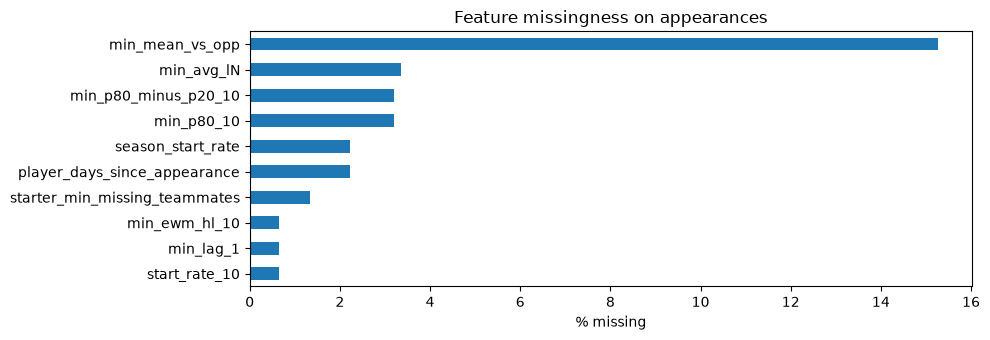

In [15]:
miss = feature_missingness(df, MIN_FEATURES)
print(missingness_summary(df, MIN_FEATURES))
display(miss)
season_miss = season_missingness(df, miss)
if season_miss.empty:
    print("Every selected feature is complete on this frame.")
else:
    display(season_miss)
    plot_missingness(miss)
    plt.show()


n=176,710  min=0.02  p50=23.65  max=56.52
Tukey fence [-9.27, 55.59]  outside=4 (0.0%)
Player minutes above 48 (overtime range): 81


,season_year,game_date,player_name,minutes,starting
62209,2021-22,2022-01-29,Pascal Siakam,56.516667,1
141903,2021-22,2022-01-29,Scottie Barnes,56.333333,1
71545,2021-22,2022-01-29,OG Anunoby,55.816667,1
92124,2021-22,2022-01-29,Gary Trent Jr.,55.650000,1
126602,2022-23,2023-03-05,Immanuel Quickley,55.100000,1
123639,2023-24,2024-04-07,Tyrese Maxey,53.950000,1
64751,2021-22,2022-01-29,Fred VanVleet,53.516667,1
155436,2024-25,2025-04-01,Christian Braun,53.166667,1


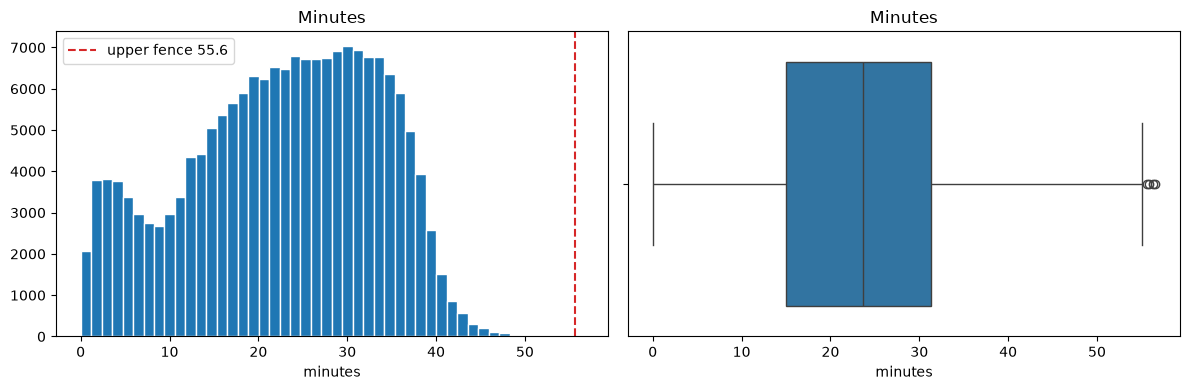

Binary inputs are omitted. A point is outside when it is past 1.5 IQR from the quartiles.


,feature,n,pct_outside,fence_low,fence_high,min,p50,max
0,player_days_since_appearance,172774,10.05,0.50,4.50,1.00,2.00,30.00
1,player_appearances_prev_7d,176710,7.79,0.50,4.50,0.00,3.00,5.00
2,min_p80_minus_p20_10,171081,3.09,-1.84,17.60,0.32,7.58,38.59
3,starter_min_missing_teammates,174350,2.01,-47.19,78.65,0.00,0.00,177.64
4,games_vs_opp,176710,1.93,-8.00,16.00,0.00,4.00,26.00
5,starter_rank,176710,0.00,-7.50,20.50,1.00,7.00,22.00
6,start_rate_10,175538,0.00,-1.50,2.50,0.00,0.30,1.00
7,season_start_rate,172776,0.00,-1.50,2.50,0.00,0.28,1.00
8,min_avg_lN,170766,0.00,-6.06,51.99,0.00,23.37,48.89
9,min_lag_1,175538,0.00,-9.20,55.60,0.00,23.68,56.52


In [16]:
outlier_stats = minutes_outlier_summary(df)
print(format_minutes_outliers(outlier_stats))
display(top_minute_rows(df))
plot_minutes(df, float(outlier_stats["fence_high"]))
plt.show()
print(
    "Binary inputs are omitted. A point is outside when it is past "
    "1.5 IQR from the quartiles."
)
display(feature_outlier_table(df, MIN_FEATURES))


In [17]:
coverage = season_coverage(df, MIN_FEATURES)
print(f"Seasons: {len(coverage)}  rows: {int(coverage['rows'].sum()):,}")
display(coverage)


Seasons: 7  rows: 176,710


,rows,players,games,first_game,last_game,pct_rows_complete,mean_missing_features
season_year,,,,,,,
2019-20,22387,529,1059,2019-10-22,2020-08-14,48.1,0.91
2020-21,23053,540,1080,2020-12-22,2021-05-16,81.8,0.31
2021-22,26035,605,1230,2021-10-19,2022-04-10,87.0,0.26
2022-23,25892,539,1230,2022-10-18,2023-04-09,89.9,0.20
2023-24,26393,572,1230,2023-10-24,2024-04-14,88.8,0.23
2024-25,26302,569,1230,2024-10-22,2025-04-13,88.1,0.23
2025-26,26648,582,1230,2025-10-21,2026-04-12,87.8,0.23


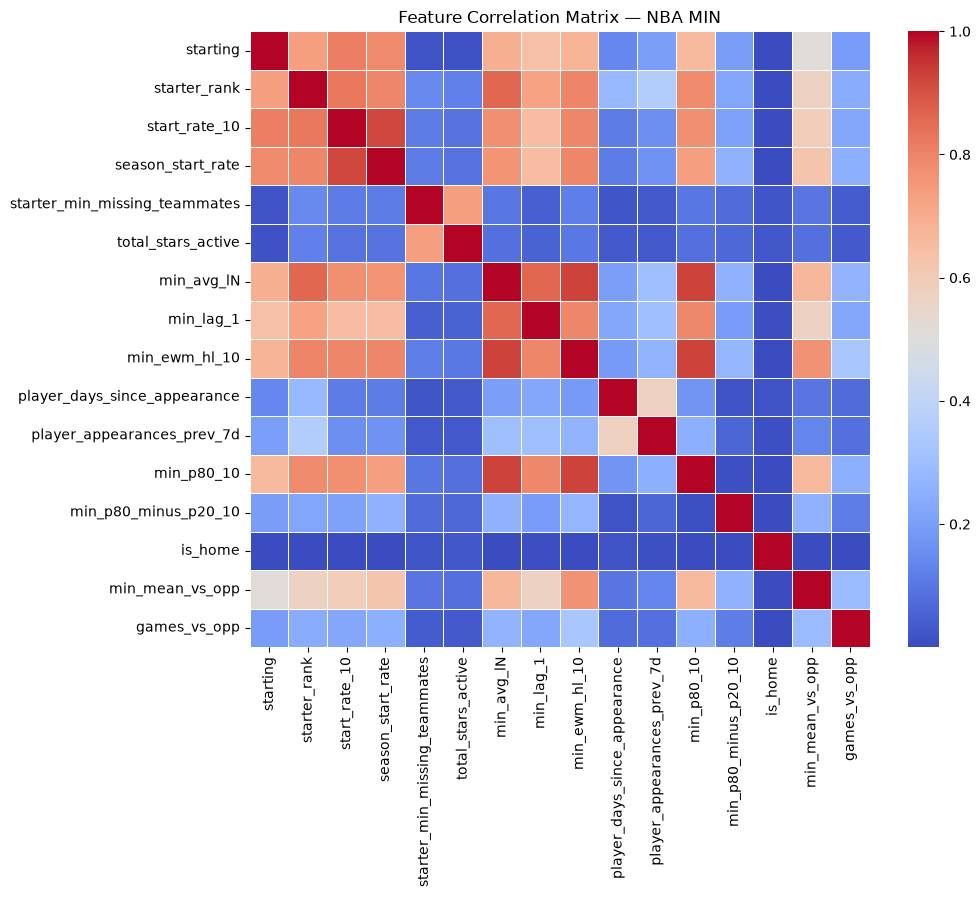

--- High Correlation Report (Threshold > 0.95) ---
No features exceed the correlation threshold.


[]

In [18]:
correlated_features = analyze_correlations(
    df, MIN_FEATURES, title="Feature Correlation Matrix — NBA MIN"
)
correlated_features


### Models

In [ ]:
# Hyperparameter tuning
# Leave commented if you don't want to retune the model

# import importlib
# import models.shared.train as train
#
# importlib.reload(train)
# tune_xgb_quantile = train.tune_xgb_quantile
#
# result = tune_xgb_quantile(X, y, n_trials=50, n_splits=3)
# XGB_PARAMS = result["best_params"]


In [19]:
tscv_results = run_timeseries_cv(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    quantiles=QUANTILES,
)
wf = run_walk_forward(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    quantiles=QUANTILES,
    n_folds=5,
)

wf_results = wf["wf_results"]
models_last = wf["models_last"]
preds_last = wf["preds_last"]
X_val_last = wf["X_val_last"]
y_val_last = wf["y_val_last"]
starting_last = wf["starting_last"]
last_fold = wf["last_fold"]


── Phase 1: TimeSeriesSplit (XGBoost) ──────────────────────────

TSCV fold 1
  n=25010
  pinball  | q0.05=0.605  q0.10=1.004  q0.20=1.585  q0.30=1.953  q0.40=2.159  q0.50=2.222  q0.60=2.152  q0.70=1.942  q0.80=1.567  q0.90=0.993  q0.95=0.593
  coverage | 80%=78.8% (target 80%)  90%=89.3% (target 90%)
  Starters   | n=11707 | pinball q50: 2.107 | 80% coverage: 78.8%
  Bench      | n=13303 | pinball q50: 2.323 | 80% coverage: 78.7%
  minute tiers by predicted q50
  <15 min    | n= 5472 | pinball q50: 2.354 | 80% coverage: 78.4%
  15-24 min  | n= 7225 | pinball q50: 2.375 | 80% coverage: 78.8%
  24-31 min  | n= 6025 | pinball q50: 2.253 | 80% coverage: 79.1%
  31+ min    | n= 6288 | pinball q50: 1.902 | 80% coverage: 78.8%

TSCV fold 2
  n=25010
  pinball  | q0.05=0.632  q0.10=1.051  q0.20=1.646  q0.30=2.022  q0.40=2.232  q0.50=2.300  q0.60=2.222  q0.70=2.000  q0.80=1.611  q0.90=1.017  q0.95=0.607
  coverage | 80%=78.1% (target 80%)  90%=88.8% (target 90%)
  Starters   | n=11824 | pinbal

In [20]:
wf_pinball, wf_coverage = score_predictions(
    y_val_last, preds_last, last_fold["fold"]
)
display(wf_pinball.round(4))
display(wf_coverage.round(4))


,split,quantile,pinball
0,WF fold 5 (2025-01-02 → 2025-04-11),0.05,0.6041
1,WF fold 5 (2025-01-02 → 2025-04-11),0.10,1.0006
2,WF fold 5 (2025-01-02 → 2025-04-11),0.20,1.5698
3,WF fold 5 (2025-01-02 → 2025-04-11),0.30,1.9336
4,WF fold 5 (2025-01-02 → 2025-04-11),0.40,2.1428
5,WF fold 5 (2025-01-02 → 2025-04-11),0.50,2.2126
6,WF fold 5 (2025-01-02 → 2025-04-11),0.60,2.1389
7,WF fold 5 (2025-01-02 → 2025-04-11),0.70,1.9230
8,WF fold 5 (2025-01-02 → 2025-04-11),0.80,1.5552
9,WF fold 5 (2025-01-02 → 2025-04-11),0.90,0.9895


,split,interval,coverage,target
0,WF fold 5 (2025-01-02 → 2025-04-11),80%,0.8077,0.8
1,WF fold 5 (2025-01-02 → 2025-04-11),90%,0.9027,0.9


In [21]:
holdout = evaluate_holdout(
    ppm_df,
    ppm_holdout,
    features=MIN_FEATURES,
    target_col=TARGET_COL,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=MIN_TIERS,
    wf_results=wf_results,
    quantiles=QUANTILES,
    fold_label=f"{HOLDOUT_SEASON} Blind Holdout",
)
models_ho = holdout["models_ho"]
preds_ho = holdout["preds_ho"]
ho_metrics = holdout["ho_metrics"]
X_ho = holdout["X_ho"]
y_ho = holdout["y_ho"]

ho_pinball, ho_coverage = score_predictions(
    y_ho, preds_ho, f"{HOLDOUT_SEASON} holdout"
)
display(ho_pinball.round(4))
display(ho_coverage.round(4))


── 2025-26 Blind Holdout ─────────────────────────────────────────────────
  Train pool: 90% rows for fit, remainder for early-stopping only; predict holdout (never in eval_set).

2025-26 Blind Holdout
  n=26648
  pinball  | q0.05=0.612  q0.10=1.016  q0.20=1.591  q0.30=1.961  q0.40=2.169  q0.50=2.233  q0.60=2.160  q0.70=1.947  q0.80=1.575  q0.90=0.996  q0.95=0.592
  coverage | 80%=80.1% (target 80%)  90%=89.9% (target 90%)
  Starters   | n=12300 | pinball q50: 2.096 | 80% coverage: 81.4%
  Bench      | n=14348 | pinball q50: 2.351 | 80% coverage: 79.1%
  minute tiers by predicted q50
  <15 min    | n= 6231 | pinball q50: 2.443 | 80% coverage: 78.1%
  15-24 min  | n= 7557 | pinball q50: 2.333 | 80% coverage: 79.8%
  24-31 min  | n= 6940 | pinball q50: 2.178 | 80% coverage: 81.2%
  31+ min    | n= 5920 | pinball q50: 1.949 | 80% coverage: 81.5%

───────────────────────────────────────────────────────
  Walk-forward pinball q50 (mean) : 2.231
  Holdout pinball q50             : 2.233
  Pi

,split,quantile,pinball
0,2025-26 holdout,0.05,0.6123
1,2025-26 holdout,0.10,1.0157
2,2025-26 holdout,0.20,1.5906
3,2025-26 holdout,0.30,1.9613
4,2025-26 holdout,0.40,2.1685
5,2025-26 holdout,0.50,2.2332
6,2025-26 holdout,0.60,2.1597
7,2025-26 holdout,0.70,1.9471
8,2025-26 holdout,0.80,1.5745
9,2025-26 holdout,0.90,0.9957


,split,interval,coverage,target
0,2025-26 holdout,80%,0.8014,0.8
1,2025-26 holdout,90%,0.8990,0.9


In [22]:
calibration = quantile_calibration(y_ho, preds_ho)
print(f"{HOLDOUT_SEASON} holdout — empirical quantile calibration")
display(calibration.round(4))


2025-26 holdout — empirical quantile calibration


,quantile,target,empirical,delta
0,0.05,0.05,0.0522,0.0022
1,0.10,0.10,0.1008,0.0008
2,0.20,0.20,0.2008,0.0008
3,0.30,0.30,0.3037,0.0037
4,0.40,0.40,0.4093,0.0093
5,0.50,0.50,0.5072,0.0072
6,0.60,0.60,0.6048,0.0048
7,0.70,0.70,0.7081,0.0081
8,0.80,0.80,0.8063,0.0063
9,0.90,0.90,0.9023,0.0023


In [23]:
n_crossed, n_rows, crossing_pairs = quantile_crossing(preds_ho)
print(
    f"{HOLDOUT_SEASON} holdout quantile crossing: "
    f"{n_crossed:,} / {n_rows:,} rows ({n_crossed / n_rows:.1%})"
)
display(crossing_pairs.round(4))


2025-26 holdout quantile crossing: 497 / 26,648 rows (1.9%)


,lower,upper,crossing_rate
0,q_0.05,q_0.10,0.0019
1,q_0.10,q_0.20,0.0011
2,q_0.20,q_0.30,0.0035
3,q_0.30,q_0.40,0.0032
4,q_0.40,q_0.50,0.0034
5,q_0.50,q_0.60,0.0031
6,q_0.60,q_0.70,0.0016
7,q_0.70,q_0.80,0.0014
8,q_0.80,q_0.90,0.0006
9,q_0.90,q_0.95,0.0008


In [24]:
tier_report = predicted_minute_tiers(y_ho, preds_ho, MIN_TIERS)
print(f"{HOLDOUT_SEASON} holdout — minute tiers by predicted q50")
display(tier_report.round(4))


2025-26 holdout — minute tiers by predicted q50


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90
0,<15 min,6231,0.2338,2.4434,0.4922,0.7814,0.8849,15.0359,19.1183
1,15-24 min,7557,0.2836,2.3334,0.4821,0.7982,0.8988,15.1426,19.7458
2,24-31 min,6940,0.2604,2.1781,0.5189,0.8115,0.9036,14.0995,18.1467
3,31+ min,5920,0.2222,1.9487,0.5414,0.8149,0.9086,12.2706,16.2069


In [25]:
score_table = pd.DataFrame([
    holdout_point_distribution("XGBoost", y_ho, preds_ho)
])
tail_calibration = pd.DataFrame(
    tail_calibration_rows("XGBoost", y_ho, preds_ho)
)
print(
    f"{HOLDOUT_SEASON} holdout — q50 RMSE and 11-knot CRPS\n"
    "  CRPS is twice the mean pinball across the trained knots"
)
display(score_table.round(4))
print(
    f"{HOLDOUT_SEASON} holdout — tail calibration\n"
    "  delta is empirical minus nominal. "
    "A positive delta means more outcomes landed in that tail than the quantile claims"
)
display(tail_calibration.round(4))


2025-26 holdout — q50 RMSE and 11-knot CRPS
  CRPS is twice the mean pinball across the trained knots


,model,rmse,crps
0,XGBoost,5.8805,3.0637


2025-26 holdout — tail calibration
  delta is empirical minus nominal. A positive delta means more outcomes landed in that tail than the quantile claims


,model,side,quantile,nominal,empirical,delta
0,XGBoost,lower,0.05,0.05,0.0522,0.0022
1,XGBoost,lower,0.10,0.10,0.1008,0.0008
2,XGBoost,upper,0.90,0.10,0.0977,-0.0023
3,XGBoost,upper,0.95,0.05,0.0488,-0.0012


In [26]:
sharp_xgb = interval_sharpness(y_ho, preds_ho)
print(f"{HOLDOUT_SEASON} holdout — interval sharpness (minutes)")
display(sharp_xgb.round(4))


2025-26 holdout — interval sharpness (minutes)


,interval,coverage,target,mean_width,median_width
0,80%,0.8014,0.8,14.2080,13.9172
1,90%,0.8990,0.9,18.3964,18.0848


### Baseline

In [27]:
report = compare_to_baselines(
    y_ho,
    preds_ho,
    ppm_holdout,
    ppm_df,
    wf_results,
)
print("1. Point accuracy versus baselines")
print(
    f"Identical holdout rows: {report['paired_n']:,}  |  "
    f"dropped {report['dropped_n']:,} with a missing baseline  |  "
    f"{report['n_boot']:,} date-clustered resamples"
)
print(
    "Mean bias is actual minus predicted. "
    f"XGBoost q50 pinball {report['q50_pinball']:.4f}. "
    "That equals half the q50 MAE."
)
display(report["point_table"].round(3))
print(
    "Paired MAE difference, clustered by game date. "
    "Negative means XGBoost q50 is lower."
)
display(report["delta_table"].round(3))
print(
    "Walk-forward MAE is 2 × q50 pinball on every validation row. "
    "Baseline MAE drops rows with no prior."
)
display(report["fold_table"].round(3))

print("\n2. Distribution quality")
knots = ", ".join(report["wis_knots"]) if report["wis_knots"] else "median only"
print(f"WIS uses the trained knots only: {knots}, plus the q50 term.")
display(report["distribution"].round(4))
print(
    f"Best baseline MAE {report['best_mae']:.3f} "
    f"({report['best_name']}) is that point forecast's CRPS."
)

print("\n3. Calibration of every quantile")
display(report["calibration"].round(4))

print("\n4. Pregame-defined subgroups")
print("Minute tiers use predicted q50.")
display(report["subgroup_table"].round(3))

print("\n5. Tail failures")
display(report["tail_table"].round(4))
print("\nChecks from this frame")
for line in report["checks"]:
    print(f"  {line}")


1. Point accuracy versus baselines
Identical holdout rows: 26,544  |  dropped 104 with a missing baseline  |  2,000 date-clustered resamples
Mean bias is actual minus predicted. XGBoost q50 pinball 2.2298. That equals half the q50 MAE.


,model,mae,median_ae,mean_bias
0,Last-game minutes,5.864,4.450,0.007
1,EWMA minutes,5.306,4.179,0.200
2,Quantile XGBoost q50,4.460,3.498,-0.116


Paired MAE difference, clustered by game date. Negative means XGBoost q50 is lower.


,comparison,delta_mae,ci_low,ci_high
0,XGBoost q50 − Last-game minutes,-1.405,-1.499,-1.319
1,XGBoost q50 − EWMA minutes,-0.847,-0.929,-0.773


Walk-forward MAE is 2 × q50 pinball on every validation row. Baseline MAE drops rows with no prior.


,fold,n,model_mae,last_game,ewma,best_baseline,model_minus_best
0,WF fold 1 (2022-11-02 → 2023-02-07),14737,4.485,5.936,5.239,5.239,-0.755
1,WF fold 2 (2023-02-07 → 2023-12-05),14919,4.490,5.988,5.463,5.463,-0.973
2,WF fold 3 (2023-12-05 → 2024-03-17),15346,4.432,5.783,5.224,5.224,-0.791
3,WF fold 4 (2024-03-17 → 2025-01-02),15441,4.479,5.830,5.374,5.374,-0.896
4,WF fold 5 (2025-01-02 → 2025-04-11),15267,4.425,5.875,5.305,5.305,-0.880


... (5 outputs left out)

,model,group,n,mae,bias,wis,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median
0,Quantile XGBoost,Confirmed starter,12300,4.192,-0.780,2.903,0.814,13.396,13.199,0.907,17.408,17.089
1,Quantile XGBoost,Bench,14348,4.702,0.475,3.202,0.791,14.904,14.787,0.893,19.244,19.174
2,Quantile XGBoost,Predicted q50 <15 min,6231,4.887,0.927,3.291,0.781,15.036,15.359,0.885,19.118,19.394
3,Quantile XGBoost,Predicted q50 15-24 min,7557,4.667,0.198,3.206,0.798,15.143,14.861,0.899,19.746,19.549
4,Quantile XGBoost,Predicted q50 24-31 min,6940,4.356,-0.531,2.998,0.812,14.099,13.910,0.904,18.147,17.856
5,Quantile XGBoost,Predicted q50 31+ min,5920,3.897,-1.074,2.720,0.815,12.271,12.142,0.909,16.207,15.989
6,Quantile XGBoost,2025-10,1791,4.546,-0.087,3.128,0.801,14.283,13.972,0.888,18.411,18.143
7,Quantile XGBoost,2025-11,4784,4.352,-0.111,2.995,0.803,14.040,13.812,0.906,18.189,17.957
8,Quantile XGBoost,2025-12,4265,4.439,-0.148,3.055,0.802,14.154,13.811,0.894,18.329,17.982
9,Quantile XGBoost,2026-01,4987,4.212,-0.245,2.899,0.823,14.129,13.874,0.914,18.323,18.014



5. Tail failures


,model,threshold,rate,n
0,Quantile XGBoost,>5 min,0.3489,9298
1,Quantile XGBoost,>10 min,0.0855,2279
2,Quantile XGBoost,>15 min,0.0194,517



Checks from this frame
  Quantile XGBoost q50 observed rate 50.7%  (target about 48–52%)
  Quantile XGBoost largest |quantile gap| 0.9%
  XGBoost q50 vs EWMA minutes: delta MAE -0.847 [-0.929, -0.773]
  WIS 3.064 (XGBoost) vs best baseline CRPS/MAE 5.306
  walk-forward folds with XGBoost MAE below the best baseline: 5 / 5
  raw quantile crossing 1.87%


### Features Analysis

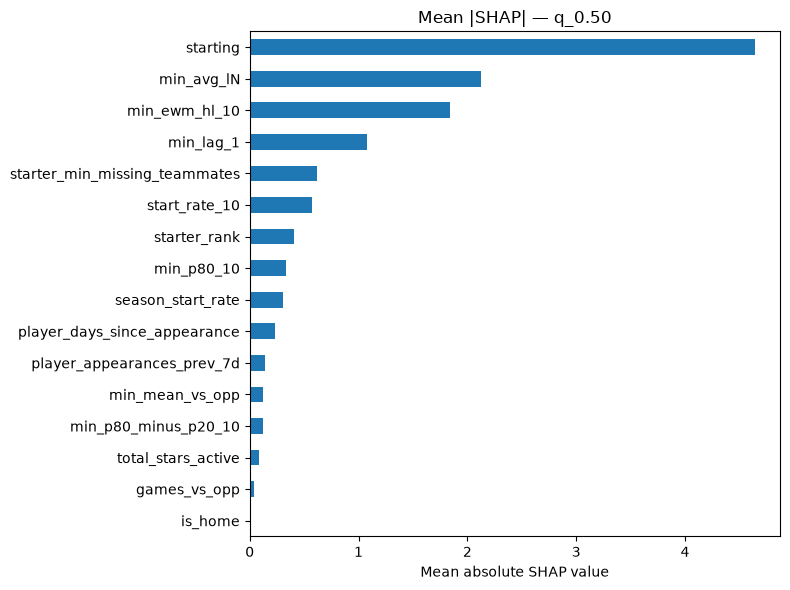

In [28]:
feat_imp = mean_absolute_shap(models_last["q_0.50"], X_val_last)
plot_shap(feat_imp)
plt.show()


In [29]:
pi_df, perm_result = permutation_importance_table(
    models_last["q_0.50"],
    X_val_last,
    y_val_last,
)
print(
    "Permutation importance (val set) — higher = more important, "
    "significant = p<0.05"
)
print(pi_df.to_string())


Permutation importance (val set) — higher = more important, significant = p<0.05
                          feature  importance      std  p_value  significant
1                        starting     0.98671  0.01192      0.0         True
2                      min_avg_lN     0.47169  0.00650      0.0         True
3                   min_ewm_hl_10     0.37119  0.00649      0.0         True
4                    starter_rank     0.19686  0.00392      0.0         True
5                       min_lag_1     0.16030  0.00486      0.0         True
6                   start_rate_10     0.08472  0.00365      0.0         True
7   starter_min_missing_teammates     0.06910  0.00353      0.0         True
8               season_start_rate     0.04624  0.00272      0.0         True
9                      min_p80_10     0.03806  0.00209      0.0         True
10   player_days_since_appearance     0.01739  0.00225      0.0         True
11             total_stars_active     0.00774  0.00092      0.0         

In [30]:
train_mask_last = last_fold["train_mask"]
val_mask_last = last_fold["val_mask"]
X_tr_last = X.loc[train_mask_last]
X_va_last = X.loc[val_mask_last]
y_tr_last = ppm_df.loc[train_mask_last, TARGET_COL]
y_va_last = ppm_df.loc[val_mask_last, TARGET_COL]

ablation_df = run_feature_ablation(
    MIN_FEATURES, X_tr_last, y_tr_last, X_va_last, y_va_last,
    xgb_params=XGB_PARAMS,
)


Baseline pinball q50 (all features): 2.2034
                          feature  ablated_pinball  delta_pinball
1                        starting           2.3001         0.0967
2                       min_lag_1           2.2204         0.0170
3   starter_min_missing_teammates           2.2193         0.0159
4                    starter_rank           2.2174         0.0139
5                   min_ewm_hl_10           2.2158         0.0124
6                   start_rate_10           2.2149         0.0114
7                      min_avg_lN           2.2105         0.0071
8              total_stars_active           2.2076         0.0042
9      player_appearances_prev_7d           2.2071         0.0036
10                     min_p80_10           2.2063         0.0028
11   player_days_since_appearance           2.2060         0.0026
12              season_start_rate           2.2056         0.0022
13                        is_home           2.2038         0.0004
14                   games_vs_op

In [31]:
feature_audit = feature_consensus(
    list(X_val_last.columns),
    feat_imp,
    pi_df,
    perm_result.importances,
    ablation_df,
)
print(feature_audit.to_string())


                          feature  mean_abs_shap  shap_rank  perm_rank  perm_importance  perm_importance_std   perm_pvalue  ablation_delta  shap_norm  perm_norm  consensus   keep
1                        starting       4.640745          1          1          0.98671              0.01192  3.531639e-57          0.0967   1.000000   1.000000   1.000000   True
2                      min_avg_lN       2.124796          2          2          0.47169              0.00650  1.625116e-55          0.0071   0.457857   0.478043   0.467950   True
3                   min_ewm_hl_10       1.835927          3          3          0.37119              0.00649  1.581559e-52          0.0124   0.395610   0.376190   0.385900   True
4                       min_lag_1       1.076255          4          5          0.16030              0.00486  1.347264e-45          0.0170   0.231914   0.162459   0.197187   True
5                    starter_rank       0.404782          7          4          0.19686              0.00

### Slice Analysis

In [32]:
dates = pd.to_datetime(ppm_holdout["game_date"])
raw_q = {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()}
blocks = regular_season_blocks(dates)

print("1. April is late regular season, not the postseason")
holdout_season = df.loc[df["season_year"].astype("string").eq(str(HOLDOUT_SEASON))]
print(holdout_season["season_type"].astype("string").value_counts(dropna=False).to_string())
print(
    f"Holdout dates {dates.min().date()} → {dates.max().date()}. "
    "The silver store only has regular_season gamelogs, so playoff games are not in this test."
)
calendar = pd.DataFrame([
    slice_score(name, mask, y_ho, raw_q) for name, mask in blocks.items()
])
display(calendar.round(3))
print(
    "Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the "
    "regular season. It is not a postseason effect, and the model has not been tested on playoff games."
)

print("\n2. Starter and bench mean bias versus median calibration")
starting = ppm_holdout["starting"].to_numpy()
role = pd.DataFrame([
    slice_score("Confirmed starter", starting == 1, y_ho, raw_q),
    slice_score("Bench", starting == 0, y_ho, raw_q),
])
display(role.round(3))
for _, row in role.iterrows():
    if row["n"] == 0:
        continue
    print(
        f"  {row['slice']}: bias {row['bias']:+.2f} min, "
        f"P(actual <= q50) {row['p_actual_le_q50']:.1%}. {role_reading(row)}."
    )

print("\n3. Monotone rearrangement")
preds_ho_mono, shift, before, after = monotone_shift(raw_q)
print(f"Crossing before {before:.2%} of rows; after rearrangement {after:.2%}.")
display(shift.round(4))
print("Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.")

print("\n4. Cold-start and missing-baseline rows")
lag = ppm_holdout["min_lag_1"].to_numpy(dtype=float)
ewma = ppm_holdout["min_ewm_hl_10"].to_numpy(dtype=float)
cold = ~np.isfinite(lag)
missing_any = cold | ~np.isfinite(ewma)
print(
    f"Missing any baseline: {int(missing_any.sum()):,} | "
    f"no prior game (min_lag_1 missing): {int(cold.sum()):,}"
)
fallback_q = role_quantile_fallback(ppm_df, preds_ho_mono, starting, cold)
missing_table = pd.DataFrame([
    slice_score("No prior game, model", cold, y_ho, raw_q),
    slice_score("No prior game, role fallback", cold, y_ho, fallback_q),
    slice_score("Any missing baseline, model", missing_any, y_ho, raw_q),
])
display(missing_table.round(3))
print(
    "Live fallback: if min_lag_1 exists, predict with the quantile model and then "
    "sort that row into increasing quantile order. "
    "If min_lag_1 is missing, do not use the tree. Use the training-pool minute quantiles "
    "for the confirmed role (starter or bench). preds_ho_live applies that rule."
)
preds_ho_live = fallback_q


1. April is late regular season, not the postseason
season_type
Regular Season    26648
Holdout dates 2025-10-21 → 2026-04-12. The silver store only has regular_season gamelogs, so playoff games are not in this test.


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,19417,4.401,-0.146,0.509,0.808,14.169,3.025
1,March 1–14,2364,4.471,-0.028,0.500,0.794,14.184,3.052
2,March 15–31,2806,4.445,-0.209,0.515,0.801,14.196,3.016
3,April regular season,2061,5.106,0.345,0.492,0.753,14.622,3.502


Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the regular season. It is not a postseason effect, and the model has not been tested on playoff games.

2. Starter and bench mean bias versus median calibration


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,Confirmed starter,12300,4.192,-0.780,0.531,0.814,13.396,2.903
1,Bench,14348,4.702,0.475,0.487,0.791,14.904,3.202


  Confirmed starter: bias -0.78 min, P(actual <= q50) 53.1%. q50 is too high: actuals fall under the median more often than 50%.
  Bench: bias +0.48 min, P(actual <= q50) 48.7%. q50 is near 50%, so the mean bias is skew around a calibrated median.

3. Monotone rearrangement
Crossing before 1.87% of rows; after rearrangement 0.00%.


,quantile,mean_abs_shift,share_changed
0,q_0.05,0.0004,0.0020
1,q_0.10,0.0005,0.0028
2,q_0.20,0.0011,0.0048
3,q_0.30,0.0016,0.0067
4,q_0.40,0.0017,0.0067
5,q_0.50,0.0017,0.0067
6,q_0.60,0.0011,0.0048
7,q_0.70,0.0008,0.0028
8,q_0.80,0.0010,0.0021
9,q_0.90,0.0007,0.0014


Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.

4. Cold-start and missing-baseline rows
Missing any baseline: 104 | no prior game (min_lag_1 missing): 104


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,"No prior game, model",104,6.197,3.043,0.442,0.808,17.517,4.141
1,"No prior game, role fallback",104,9.345,-6.079,0.769,0.712,23.154,5.653
2,"Any missing baseline, model",104,6.197,3.043,0.442,0.808,17.517,4.141


Live fallback: if min_lag_1 exists, predict with the quantile model and then sort that row into increasing quantile order. If min_lag_1 is missing, do not use the tree. Use the training-pool minute quantiles for the confirmed role (starter or bench). preds_ho_live applies that rule.


### Error Analysis

In [33]:
miss = build_miss_frame(df, ppm_holdout, preds_ho)
way_off = miss["abs_error"] >= 10
print(
    f"{HOLDOUT_SEASON} holdout: {int(way_off.sum()):,} / {len(miss):,} rows "
    f"missed by 10+ minutes ({way_off.mean():.1%}). "
    f"Median |error| {miss['abs_error'].median():.1f}."
)
print("actual − q50 > 0 means he played more than the median prediction.")


def show_misses(frame, title):
    print(title)
    display(miss_view(frame))


show_misses(
    miss.nsmallest(20, "error"),
    "\nPlayed much less than q50 (sat, foul trouble, blowout rest)",
)
show_misses(
    miss.nlargest(20, "error"),
    "\nPlayed much more than q50 (garbage time, overtime, unexpected run)",
)
biggest = pd.concat(
    [miss.nsmallest(20, "error"), miss.nlargest(20, "error")],
    ignore_index=True,
)
print("\nHints on those 40 misses")
print(biggest["hint"].replace("", "unlabeled").value_counts().to_string())
games = rotation_team_games(miss)
print("\nTeam-games where the most rotation players (q50 ≥ 15) missed by 10+ minutes")
display(
    games.head(15)[
        [
            "date",
            "game",
            "score",
            "wl",
            "margin",
            "ot",
            "n_rotation",
            "n_off_10",
            "mean_abs_error",
            "players_off_by_10",
        ]
    ]
)


2025-26 holdout: 2,279 / 26,648 rows missed by 10+ minutes (8.6%). Median |error| 3.5.
actual − q50 > 0 means he played more than the median prediction.

Played much less than q50 (sat, foul trouble, blowout rest)


,date,player,game,score,wl,actual_min,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,pts,+/-,margin,last_game_min,pregame_|spread|,ot,hint
11244,2026-01-03,Alperen Sengun,HOU @ DAL,104-110,L,1.1,34.8,-33.7,27–39,0,0,1,0,0,-6,33.7,8.0,False,outside 10–90
831,2025-10-26,Anthony Edwards,MIN vs. IND,114-110,W,3.1,36.1,-33.0,30–40,0,0,1,5,8,4,34.7,12.0,False,outside 10–90
26387,2026-04-12,Mikal Bridges,NYK vs. CHA,96-110,L,0.4,33.0,-32.6,26–37,1,0,1,0,0,-14,33.1,14.5,False,outside 10–90
12983,2026-01-14,Jalen Brunson,NYK @ SAC,101-112,L,5.0,35.7,-30.8,29–40,0,0,1,4,-8,-11,36.6,11.0,False,outside 10–90
18732,2026-02-24,Jalen Johnson,ATL vs. WAS,119-98,W,5.6,36.2,-30.6,29–40,1,1,1,5,2,21,37.8,12.0,False,blowout rest
18402,2026-02-22,Deni Avdija,POR @ PHX,92-77,W,1.0,31.6,-30.6,24–37,0,0,1,0,0,15,30.4,3.5,False,blowout rest
4018,2025-11-14,OG Anunoby,NYK vs. MIA,140-132,W,5.1,35.5,-30.4,30–40,1,0,1,2,1,8,33.9,6.5,False,outside 10–90
22192,2026-03-17,Cade Cunningham,DET @ WAS,130-117,W,5.3,35.7,-30.3,29–40,1,3,1,6,0,13,37.2,19.5,False,outside 10–90
1319,2025-10-29,Anthony Davis,DAL vs. IND,107-105,W,6.6,35.5,-28.9,29–39,0,0,1,4,-3,2,38.1,6.0,False,outside 10–90
20535,2026-03-07,Anthony Black,ORL @ MIN,119-92,W,2.0,30.7,-28.7,22–37,0,1,1,0,2,27,23.8,6.5,False,blowout rest



Played much more than q50 (garbage time, overtime, unexpected run)


,date,player,game,score,wl,actual_min,pred_q50,actual − q50,q10–q90,fouls,fouls_drawn,starting,pts,+/-,margin,last_game_min,pregame_|spread|,ot,hint
22887,2026-03-21,Kennedy Chandler,UTA vs. PHI,116-126,L,37.2,5.3,31.9,1–17,2,4,0,19,-4,-10,2.6,5.5,False,outside 10–90
7346,2025-12-05,Ethan Thompson,IND @ CHI,120-105,W,34.3,5.8,28.5,1–17,4,1,0,11,25,15,3.2,4.5,False,garbage time
21632,2026-03-13,Bez Mbeng,UTA @ POR,114-124,L,33.8,5.7,28.2,1–19,1,1,0,4,-28,-10,NaN,15.5,False,outside 10–90
21046,2026-03-10,Ron Harper Jr.,BOS @ SAS,116-125,L,33.2,6.0,27.1,1–17,0,1,0,22,-12,-9,4.3,3.5,False,outside 10–90
17980,2026-02-19,Kadary Richmond,WAS vs. IND,112-105,W,29.4,4.2,25.2,1–15,1,3,0,13,8,7,6.1,2.0,False,outside 10–90
5318,2025-11-22,Andre Jackson Jr.,MIL vs. DET,116-129,L,28.9,3.8,25.1,1–11,3,2,0,6,-3,-13,3.6,8.0,False,outside 10–90
21421,2026-03-12,Jalen Slawson,IND vs. PHX,108-123,L,31.7,6.8,25.0,2–12,2,3,0,10,6,-15,10.8,9.0,False,garbage time
17910,2026-02-19,Alondes Williams,WAS vs. IND,112-105,W,27.7,2.9,24.9,1–12,1,2,0,6,12,7,3.7,2.0,False,outside 10–90
1328,2025-10-29,Dwight Powell,DAL vs. IND,107-105,W,29.4,4.8,24.6,1–15,4,8,0,18,12,2,2.2,6.0,False,outside 10–90
343,2025-10-23,Ben Sheppard,IND vs. OKC,135-141,L,39.0,14.6,24.4,5–24,6,3,0,15,-5,-6,20.4,7.5,True,overtime



Hints on those 40 misses
hint
outside 10–90    26
garbage time      7
blowout rest      4
overtime          3

Team-games where the most rotation players (q50 ≥ 15) missed by 10+ minutes


,date,game,score,wl,margin,ot,n_rotation,n_off_10,mean_abs_error,players_off_by_10
2385,2026-04-12,DAL vs. CHI,149-128,W,21.0,False,8,7,14.8,"Cooper Flagg (-24, 1 PF), Moussa Cisse (+21, 4..."
2265,2026-04-05,WAS @ BKN,115-121,L,-6.0,False,8,6,13.3,"Sharife Cooper (-20, 0 PF), Jamir Watkins (+16..."
1621,2026-02-21,PHX vs. ORL,113-110,W,3.0,True,10,6,11.5,"Dillon Brooks (-22, 1 PF), Royce O'Neale (+17,..."
238,2025-10-27,PHX @ UTA,134-138,L,-4.0,True,8,6,11.0,"Royce O'Neale (+14, 5 PF), Collin Gillespie (+..."
1450,2026-02-04,DEN @ NYK,127-134,L,-7.0,True,9,6,10.5,"Spencer Jones (-19, 1 PF), Christian Braun (+1..."
2298,2026-04-07,BKN vs. MIL,96-90,W,6.0,False,9,6,9.6,"Drake Powell (+13, 1 PF), Trevon Scott (+13, 3..."
8,2025-10-23,IND vs. OKC,135-141,L,-6.0,True,6,5,13.0,"Obi Toppin (+24, 3 PF), Isaiah Jackson (-17, 4..."
2224,2026-04-01,GSW vs. SAS,113-127,L,-14.0,False,7,5,12.3,"Nate Williams (+20, 5 PF), Brandin Podziemski ..."
1465,2026-02-05,WAS @ DET,126-117,W,9.0,False,8,5,11.8,"Sharife Cooper (+19, 3 PF), Kyshawn George (-1..."
1,2025-10-21,OKC vs. HOU,125-124,W,1.0,True,7,5,11.3,"Luguentz Dort (+16, 4 PF), Alex Caruso (+14, 2..."


### Save Exploratory Artifact

In [34]:
metadata = exploratory_metadata(ppm_df, ppm_holdout, ho_metrics, wf_results)
display(metadata)


{'created_at': '2026-10-25T22:00:38.285525+00:00',
 'status': 'exploratory',
 'model_name': 'quantile_xgboost',
 'artifact_stem': 'min_nba_model',
 'features': ['starting',
  'starter_rank',
  'start_rate_10',
  'season_start_rate',
  'starter_min_missing_teammates',
  'total_stars_active',
  'min_avg_lN',
  'min_lag_1',
  'min_ewm_hl_10',
  'player_days_since_appearance',
  'player_appearances_prev_7d',
  'min_p80_10',
  'min_p80_minus_p20_10',
  'is_home',
  'min_mean_vs_opp',
  'games_vs_opp'],
 'label': 'minutes',
 'label_rule': 'minutes > 0',
 'quantiles': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
 'point_forecast': 0.5,
 'interval': [0.1, 0.9],
 'params': {'objective': 'reg:quantileerror',
  'n_estimators': 1198,
  'max_depth': 4,
  'learning_rate': 0.10831429032170246,
  'subsample': 0.7978199709619458,
  'colsample_bytree': 0.8074992328271139,
  'reg_alpha': 4.019094324629617,
  'reg_lambda': 0.7852113626147341,
  'min_child_weight': 8,
  'early_stopping_rounds

In [35]:
save_path = save_model_bundle(
    models_ho,
    train_df=ppm_df,
    holdout_df=ppm_holdout,
    wf_results=wf_results,
    ho_metrics=ho_metrics,
    features=MIN_FEATURES,
    artifact_stem=ARTIFACT_STEM,
    metadata=metadata,
)
bundle = load_model_bundle(save_path)
models_loaded = bundle["quantile_models"]
assert list(X_ho.columns) == list(bundle["feature_names"])
scores = loaded_holdout_scores(models_loaded, X_ho, y_ho)
print("Saved quantiles:", ", ".join(scores["quantiles"]))
print(f"Loaded model pinball q50 (holdout): {scores['pinball_q50']:.3f}")
print(f"Loaded model 80% coverage (holdout): {scores['coverage_80']:.1%}")
print(f"Trained on data up to      : {bundle['train_end'].date()}")
print(f"Holdout through            : {bundle['val_end'].date()}")


Saved to /Users/alexgonzalez/Documents/nba_quant/models/saved_models/min_nba_model_2026-04-12.joblib
Loaded /Users/alexgonzalez/Documents/nba_quant/models/saved_models/min_nba_model_2026-04-12.joblib
Saved quantiles: q_0.05, q_0.10, q_0.20, q_0.30, q_0.40, q_0.50, q_0.60, q_0.70, q_0.80, q_0.90, q_0.95
Loaded model pinball q50 (holdout): 2.233
Loaded model 80% coverage (holdout): 80.1%
Trained on data up to      : 2025-04-13
Holdout through            : 2026-04-12


In [36]:
PREDICTIONS_PATH = ROOT / "data/oos/nba/minutes_predictions.parquet"
predictions = build_oos_predictions(wf, ppm_df, ppm_holdout, preds_ho)
write_oos_predictions(predictions, PREDICTIONS_PATH)
print(f"Wrote {len(predictions):,} rows to {PREDICTIONS_PATH.relative_to(ROOT)}")
predictions.groupby("window_id").agg(
    rows=("game_id", "size"),
    first=("game_date", "min"),
    last=("game_date", "max"),
)


Wrote 102,358 rows to data/oos/nba/minutes_predictions.parquet


,rows,first,last
window_id,,,
-1,26648,2025-10-21,2026-04-12
1,14737,2022-11-03,2023-02-07
2,14919,2023-02-08,2023-12-05
3,15346,2023-12-06,2024-03-17
4,15441,2024-03-18,2025-01-02
5,15267,2025-01-03,2025-04-11


### Conclusion